# 07: Expected Loss Calculation and Portfolio Analysis

This notebook computes the Expected Loss (EL) for every loan in the portfolio and validates the results through economic coherence checks and segment-level analysis. Comparisons with observed losses use matured loans only, the loans whose outcome is complete (see `01_data_diagnosis`); for younger loans the observed losses are still accruing.

$$
\text{EL} = PD \times \frac{LGD}{100} \times EAD
$$

**Input:** `data/processed/checkpoint_df_master_with_PD_LGD.pkl`  
**Output:** `data/processed/portfolio_with_EL.pkl`

## Libraries

In [1]:
# Run from the repository root so that data/, models/ and src/ resolve the same way
# whether the notebook is opened from the root or from production_notebooks/.
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "production_notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os

from readme_figures import plot_el_by_quartile, plot_key_metrics, interest_rate_ranges

## 1. Load Checkpoint

In [3]:
with open("data/processed/checkpoint_df_master_with_PD_LGD.pkl", "rb") as f:
    data = pickle.load(f)
df_master_features = data["df_master_features"]

print(f"Portfolio shape: {df_master_features.shape}")
print(f"Columns with model outputs: {[c for c in df_master_features.columns if c in ['PD', 'LGD', 'EAD']]}")

Portfolio shape: (2139643, 57)
Columns with model outputs: ['EAD', 'PD', 'LGD']


## 2. Expected Loss Calculation

LGD is divided by 100 to convert from percentage scale (0-100) to proportion (0-1), consistent with `Target_Variable_Loss = 100 * net_loss / EAD` (see `01_data_diagnosis`). EL is a lifetime figure: the loss expected over the life of each loan, not an annual rate.

In [4]:
df_master_features["EL"] = (
    df_master_features["PD"] *
    (df_master_features["LGD"] / 100) *
    df_master_features["EAD"]
)

print(f"EL computed for {len(df_master_features):,} loans")
print(f"Total EL       : {df_master_features['EL'].sum():,.0f}")
print(f"Mean EL / loan : {df_master_features['EL'].mean():,.2f}")

EL computed for 2,139,643 loans
Total EL       : 2,904,840,912
Mean EL / loan : 1,357.63


## 3. Validation

### 3.1 EL vs Observed Loss (matured loans)

For a matured loan the lifetime outcome is known, so its EL can be compared with the loss it actually produced. Loans that have not reached maturity are left out of this comparison: their observed losses are incomplete.

In [5]:
mask_default = df_master_features["Target_Variable_Default"] == 1
matured = df_master_features["is_matured"] == 1

# Observed loss: realised LGD x EAD on the loans that defaulted
observed_loss_dev = (
    df_master_features.loc[matured & mask_default, "EAD"] *
    df_master_features.loc[matured & mask_default, "Target_Variable_Loss"] / 100
).sum()
expected_loss_dev = df_master_features.loc[matured, "EL"].sum()
expected_loss = df_master_features["EL"].sum()      # whole portfolio, used below

print(f"Matured loans                    : {matured.sum():,}")
print(f"Observed loss (matured, defaulted): {observed_loss_dev:,.0f}")
print(f"Expected loss (matured)          : {expected_loss_dev:,.0f}")
print(f"EL / observed loss (matured)     : {expected_loss_dev / observed_loss_dev:.4f}")

Matured loans                    : 676,113
Observed loss (matured, defaulted): 700,895,593
Expected loss (matured)          : 685,457,677
EL / observed loss (matured)     : 0.9780


### 3.1b Out-of-sample check on the test loans

The comparison above covers all matured loans, including those the models were trained on, so it is partly in-sample. The same comparison restricted to the PD test split (matured loans unseen by the PD model and its calibrator) is the honest version.

In [6]:
test = df_master_features["split_PD"] == "test"

observed_loss_test = (
    df_master_features.loc[test & mask_default, "EAD"] *
    df_master_features.loc[test & mask_default, "Target_Variable_Loss"] / 100
).sum()
expected_loss_test = df_master_features.loc[test, "EL"].sum()

print(f"Test loans                   : {test.sum():,}")
print(f"Observed loss (test, default): {observed_loss_test:,.0f}")
print(f"Expected loss (test)         : {expected_loss_test:,.0f}")
print(f"EL / observed loss (test)    : {expected_loss_test / observed_loss_test:.4f}")

Test loans                   : 135,223
Observed loss (test, default): 140,684,130
Expected loss (test)         : 136,754,952
EL / observed loss (test)    : 0.9721


### 3.2 EL Decomposition by Population (matured loans)

In [7]:
el_default    = df_master_features.loc[matured & mask_default,  "EL"].sum()
el_no_default = df_master_features.loc[matured & ~mask_default, "EL"].sum()

print(f"EL defaulted loans    : {el_default:,.0f}")
print(f"EL non-defaulted loans: {el_no_default:,.0f}")
print(f"% EL from non-defaulted: {el_no_default / expected_loss_dev * 100:.2f}%")

EL defaulted loans    : 144,350,067
EL non-defaulted loans: 541,107,610
% EL from non-defaulted: 78.94%


### 3.3 EL Rate

The portfolio EL rate covers every loan. It is also shown separately for matured loans and for loans still running.

In [8]:
total_ead = df_master_features["EAD"].sum()
el_rate   = expected_loss / total_ead * 100

print(f"Total EAD (portfolio): {total_ead:,.0f}")
print(f"Total EL (portfolio) : {expected_loss:,.0f}")
print(f"EL rate (portfolio)  : {el_rate:.2f}%")

by_maturity = df_master_features.groupby("is_matured").agg(
    loans=("EAD", "size"), EAD=("EAD", "sum"), EL=("EL", "sum")
)
by_maturity["EL_rate_pct"] = by_maturity["EL"] / by_maturity["EAD"] * 100
by_maturity = by_maturity.drop(columns="EL").rename(index={0: "not matured", 1: "matured"})
print(by_maturity.round(2))

Total EAD (portfolio): 31,628,836,375
Total EL (portfolio) : 2,904,840,912
EL rate (portfolio)  : 9.18%


               loans          EAD  EL_rate_pct
is_matured                                    
not matured  1463530  22800332425         9.73
matured       676113   8828503950         7.76


### 3.4 EL Distribution

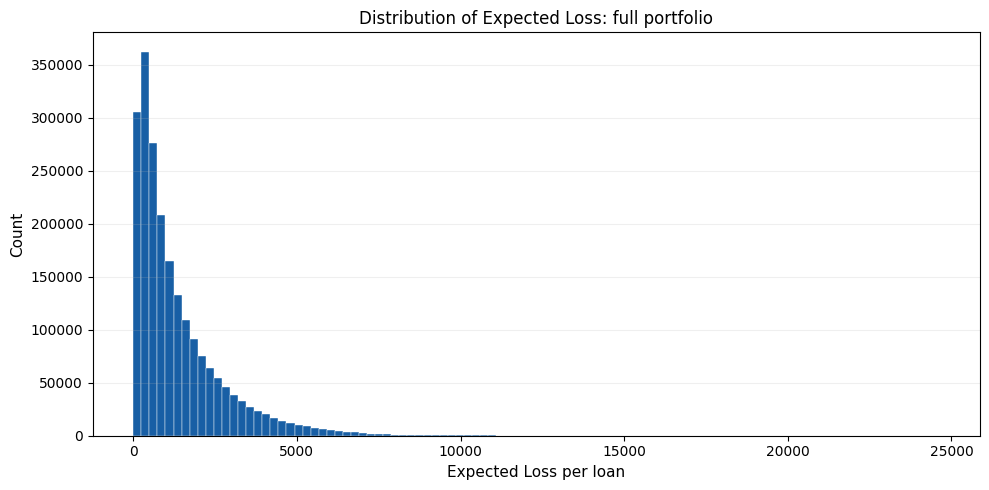

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_master_features["EL"], bins=100, color="#185FA5", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Expected Loss per loan", fontsize=11)
ax.set_ylabel("Count", fontsize=11)
ax.set_title("Distribution of Expected Loss: full portfolio", fontsize=12)
ax.grid(True, alpha=0.2, axis="y")
plt.tight_layout()
plt.show()

## 4. Portfolio Analysis by Segment

### 4.1 EL Rate by Loan Term

In [10]:
sums_by_term = df_master_features.groupby("loan_term_months")[["EL", "EAD"]].sum()
el_by_term = (sums_by_term["EL"] / sums_by_term["EAD"] * 100).round(2)
print(el_by_term)

# 60-month loans should show higher EL rate than 36-month loans
assert el_by_term[60] > el_by_term[36], "EL rate ordering violated: 60m should exceed 36m"

loan_term_months
36     7.30
60    12.16
dtype: float64


### 4.2 EL Rate by Interest Rate Quartile

In [11]:
df_master_features["interest_rate_q"] = pd.qcut(
    df_master_features["interest_rate"], q=4, labels=["Q1", "Q2", "Q3", "Q4"]
)

sums_by_rate = df_master_features.groupby("interest_rate_q", observed=True)[["EL", "EAD"]].sum()
el_by_rate = (sums_by_rate["EL"] / sums_by_rate["EAD"] * 100).round(2)
print(el_by_rate)

# Q4 (highest rates) must have higher EL rate than Q1 (lowest rates)
assert el_by_rate["Q4"] > el_by_rate["Q1"], "EL rate ordering violated: Q4 should exceed Q1"

interest_rate_q
Q1     2.88
Q2     6.51
Q3    10.07
Q4    16.27
dtype: float64


Saved assets\el_by_quartile.png


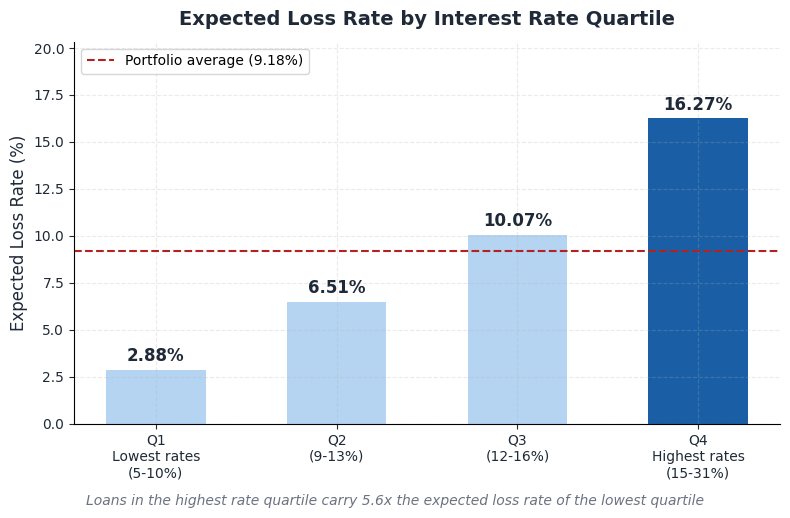

In [12]:
# EL rate by interest rate quartile (also saved for the README)
plot_el_by_quartile(el_by_rate, el_rate, interest_rate_ranges(df_master_features))
plt.show()

### 4.3 PD Calibration Check by Segment (matured loans)

Observed default rates are only complete for matured loans, so the check is restricted to them.

In [13]:
# PD mean vs observed default rate per interest rate quartile, matured loans
calibration_check = df_master_features[matured].groupby("interest_rate_q", observed=True).agg(
    pd_mean=("PD", "mean"),
    default_rate=("Target_Variable_Default", "mean")
).round(4)

print(calibration_check)

                 pd_mean  default_rate
interest_rate_q                       
Q1                0.0614        0.0646
Q2                0.1242        0.1241
Q3                0.1830        0.1793
Q4                0.2580        0.2604


### 4.4 Headline metrics for the README

Saved assets\key_metrics.png


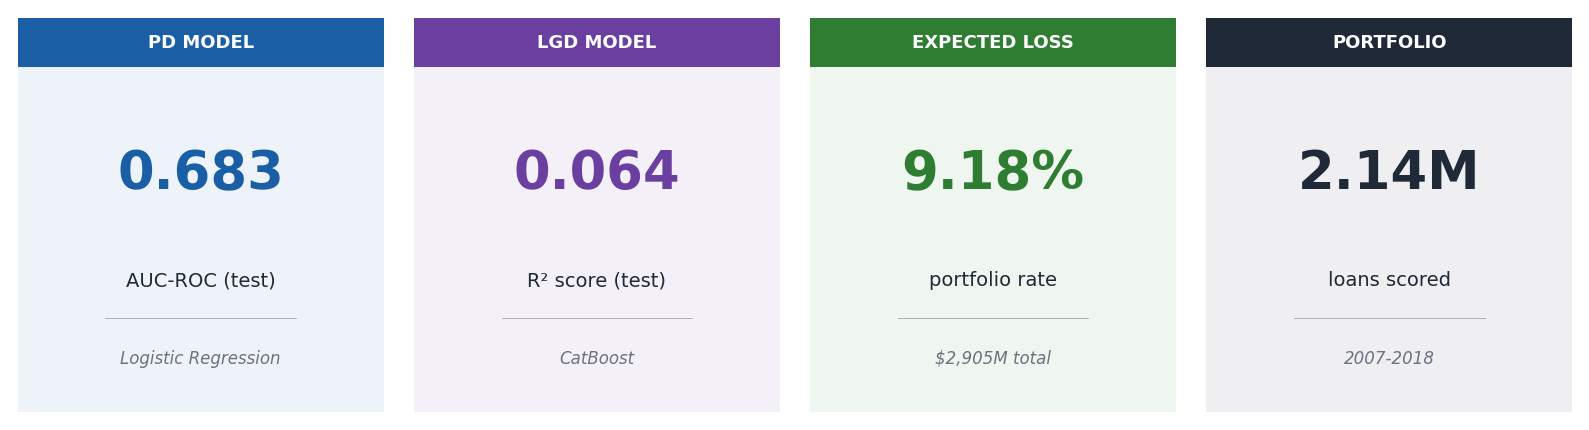

In [14]:
# Test metrics of the selected PD and LGD models (selected by cross-validation in 05 and 06)
results_PD  = pd.read_csv("models/PD_model_comparison.csv", index_col="model")
results_LGD = pd.read_csv("models/LGD_model_comparison.csv", index_col="model")
best_PD, best_LGD = results_PD["cv_auc"].idxmax(), results_LGD["cv_rmse"].idxmin()

years = f"{int(df_master_features['issue_date_year'].min())}-{int(df_master_features['issue_date_year'].max())}"
plot_key_metrics(
    pd_auc=results_PD.loc[best_PD, "auc"], pd_model=best_PD,
    lgd_r2=results_LGD.loc[best_LGD, "r2"], lgd_model=best_LGD,
    el_rate=el_rate, el_total=expected_loss,
    n_loans=len(df_master_features), years=years,
)
plt.show()

## 5. Save Final Portfolio

In [15]:
os.makedirs("data/processed", exist_ok=True)

with open("data/processed/portfolio_with_EL.pkl", "wb") as f:
    pickle.dump({"df_master_features": df_master_features}, f)

print(f"Final portfolio saved. Shape: {df_master_features.shape}")
print(f"Columns: {df_master_features.columns.tolist()}")

Final portfolio saved. Shape: (2139643, 59)
Columns: ['Target_Variable_Default', 'Target_Variable_Loss', 'EAD', 'interest_rate', 'monthly_payment', 'grade', 'emp_title', 'emp_length', 'home_ownership_status', 'annual_income', 'verification_status', 'loan_purpose', 'addr_state', 'dept_paym_income_ratio', 'num_30+_delinq_in_2yrs', 'num_inq_in_6mths', 'num_open_credit_lines', 'num_derogatory_pub_rec', 'total_credit_revolving_bal', 'used_credit_share', 'tot_num_credit_lines', 'initial_list_status', 'remaining_princ_for_tot_amnt_fund', 'paym_rec_for_tot_amnt_fund', 'princ_rec', 'interest_rec', 'num_open_trades_in_6mths', 'num_installment_acc_op_in_12mths', 'num_installment_acc_op_in_24mths', 'num_rev_trades_op_in_12mths', 'num_rev_trades_op_in_24mths', 'max_bal_owed', 'bal_to_cred_lim', 'num_inq', 'num_inq_in_12mths', 'loan_term_months', 'issue_date_month', 'issue_date_year', 'region_code', 'earliest_cr_line_month', 'earliest_cr_line_year', 'is_matured', 'has_late_fees_PD', 'late_fees_rec_L